# 424 – Using a Trained qGAN: Pricing a European Call Option

Why train a generator at all?  Because a trained generator is a **cheap way to load a
probability distribution into a quantum state** – and many quantum algorithms need exactly
that as their input.  Here the distribution is the uncertain future price of a stock, and the
algorithm is **Quantum Amplitude Estimation (QAE)**, which estimates an expected value with
quadratically fewer samples than classical Monte Carlo.

**The problem.**  A *European call option* gives the right to buy a stock at maturity for the
*strike price* $K$.  Its payoff is $\max(0, S_T - K)$, where $S_T$ is the (uncertain) spot price
at maturity.  The fair price of the option is the **expected payoff**
$\mathbb{E}[\max(0, S_T - K)]$.

**The pipeline**
1. a qGAN-trained circuit loads the distribution of $S_T$ into 3 qubits (`421` showed how to
   train one; here we use parameters from the original paper);
2. a payoff circuit rotates an extra qubit so that the probability of measuring it as $|1\rangle$
   encodes the payoff;
3. QAE estimates that probability.

Paper: Zoufal, Lucchi, Woerner, *Quantum Generative Adversarial Networks for learning and
loading random distributions*, npj Quantum Information 5, 103 (2019).

**Prerequisites:** `421`, `302-Simple Amplitude Estimation`.

In [ ]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')

Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit.library import LinearAmplitudeFunctionGate, StatePreparation, n_local
from qiskit.primitives import StatevectorSampler
from qiskit.quantum_info import Statevector
from qiskit_algorithms import EstimationProblem, IterativeAmplitudeEstimation

Two small helpers.  (They used to live in `qiskit-finance`; they are short enough to write out.)

* `NormalDistribution` – loads a discretised normal distribution into the amplitudes; it is the
  *initial state* of the generator in the paper.
* `EuropeanCallExpectedValue` – the payoff circuit.  The payoff $\max(0, x-K)$ is piecewise
  linear, and `LinearAmplitudeFunctionGate` turns a piecewise-linear function $f$ into a
  rotation so that $P(\text{objective qubit} = 1) \approx$ a rescaled $f(x)$.

In [3]:
def NormalDistribution(num_qubits, mu=0., sigma=1., bounds=(-1., 1.)):
    """Load a normal distribution, discretised on 2^num_qubits grid points, into the amplitudes."""
    x = np.linspace(bounds[0], bounds[1], 2 ** num_qubits)
    probabilities = np.exp(-(x - mu) ** 2 / (2 * sigma ** 2))
    probabilities /= probabilities.sum()
    qc = QuantumCircuit(num_qubits, name='P(X)')
    qc.append(StatePreparation(np.sqrt(probabilities)), range(num_qubits))
    return qc


class EuropeanCallExpectedValue(QuantumCircuit):
    """Payoff max(0, S_T - K) of a European call as a piecewise-linear amplitude function."""

    def __init__(self, num_state_qubits, strike_price, rescaling_factor, bounds):
        num_values = 2 ** num_state_qubits
        # map the strike price onto the grid {0, ..., 2^n - 1}
        strike = int(np.ceil((strike_price - bounds[0]) / (bounds[1] - bounds[0]) * (num_values - 1)))
        objective = LinearAmplitudeFunctionGate(num_state_qubits, slope=[0, 1], offset=[0, 0],
                                                domain=(0, num_values - 1), image=(0, num_values - 1 - strike),
                                                rescaling_factor=rescaling_factor, breakpoints=[0, strike])
        super().__init__(objective.num_qubits, name='ECEV')
        self.append(objective, self.qubits)
        self._objective = objective

    def post_processing(self, scaled_value):
        """Undo the rescaling: map the measured probability back to the expected payoff."""
        return self._objective.post_processing(scaled_value)

## Step 1 – The uncertainty model (the trained generator)

The Black–Scholes model assumes $S_T$ is **log-normally** distributed.  The generator from the
paper starts from a normal distribution on the grid $\{0, 1, \dots, 7\}$ and applies a trained
`n_local` layer of $R_Y$ rotations and $CZ$ gates – 6 parameters, `g_params`.

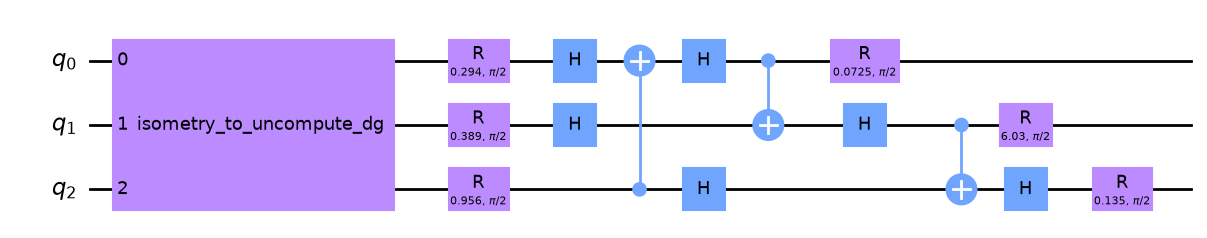

In [4]:
bounds = np.array([0., 7.])
num_qubits = 3

# parameters of the trained generator (from the qGAN paper)
g_params = [0.29399714, 0.38853322, 0.9557694, 0.07245791, 6.02626428, 0.13537225]

init_dist = NormalDistribution(num_qubits, mu=1., sigma=1., bounds=bounds)
var_form = n_local(num_qubits, 'ry', 'cz', entanglement='circular', reps=1)
theta = list(var_form.parameters)

g_circuit = init_dist.compose(var_form)
uncertainty_model = g_circuit.assign_parameters(dict(zip(theta, g_params)))
uncertainty_model.decompose().draw(output='mpl', style='clifford')

Compare the distribution the circuit loads with the target log-normal distribution:

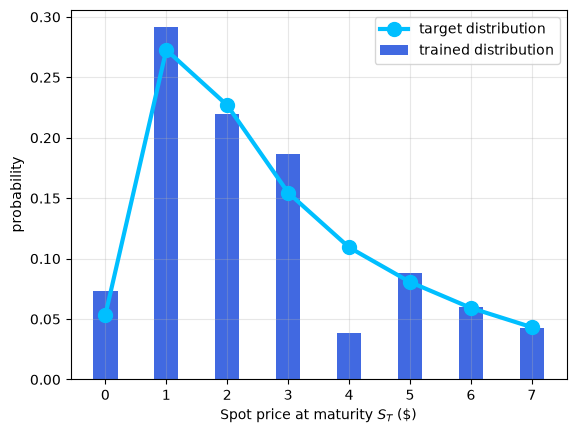

In [5]:
values = np.linspace(bounds[0], bounds[1], 2 ** num_qubits)
probabilities = Statevector(uncertainty_model).probabilities()

# target: log-normal samples, rounded to the grid
log_normal = np.round(np.random.default_rng(0).lognormal(mean=1, sigma=1, size=100000))
log_normal = log_normal[log_normal <= bounds[1]]
target = np.array([np.sum(log_normal == v) for v in values]) / len(log_normal)

plt.bar(values, probabilities, width=0.4, label='trained distribution', color='royalblue')
plt.plot(values, target, '-o', color='deepskyblue', label='target distribution', linewidth=3, markersize=10)
plt.xticks(values)
plt.grid(alpha=0.3)
plt.xlabel(r'Spot price at maturity $S_T$ (\$)')
plt.ylabel('probability')
plt.legend()
plt.show()

## Step 2 – The payoff and its exact expected value

With strike price $K = 2$ the payoff on the grid is $(0, 0, 0, 1, 2, 3, 4, 5)$.  Because the
distribution is small we can compute the expected payoff **exactly** – the reference value
that QAE should reproduce.

exact expected payoff w.r.t. the target distribution : 1.0681
exact expected payoff w.r.t. the trained distribution: 0.9805


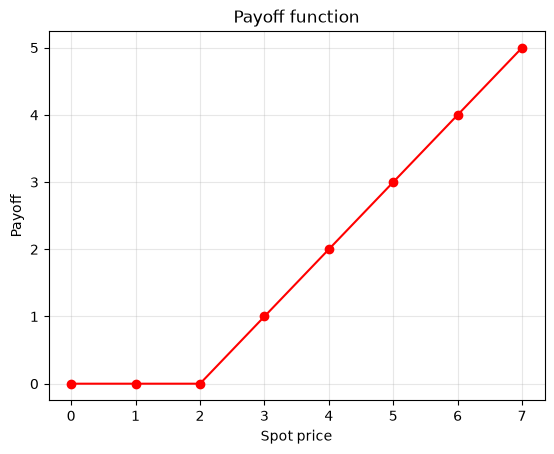

In [6]:
strike_price = 2
payoff = np.maximum(0, values - strike_price)

ep_target = target @ payoff
ep_trained = probabilities @ payoff
print(f"exact expected payoff w.r.t. the target distribution : {ep_target:.4f}")
print(f"exact expected payoff w.r.t. the trained distribution: {ep_trained:.4f}")

plt.plot(values, payoff, 'ro-')
plt.grid(alpha=0.3)
plt.title('Payoff function')
plt.xlabel('Spot price')
plt.ylabel('Payoff')
plt.xticks(values)
plt.show()

## Step 3 – Quantum amplitude estimation

The **state preparation** $\mathcal{A}$ for QAE is the uncertainty model followed by the payoff
circuit.  The approximation scaling `c_approx` controls how linear the rotation is: smaller =
more accurate but a smaller amplitude to estimate.

`IterativeAmplitudeEstimation` (IQAE) runs Grover-like circuits of increasing depth until the
estimate reaches the target precision $\epsilon$ with confidence $1-\alpha$.

In [7]:
c_approx = 0.25
european_call_objective = EuropeanCallExpectedValue(num_qubits, strike_price=strike_price,
                                                    rescaling_factor=c_approx, bounds=bounds)
european_call = european_call_objective.compose(uncertainty_model, front=True)

epsilon = 0.01   # target precision
alpha = 0.05     # confidence level 95 %

problem = EstimationProblem(state_preparation=european_call,
                            objective_qubits=[num_qubits],
                            post_processing=european_call_objective.post_processing)
ae = IterativeAmplitudeEstimation(epsilon_target=epsilon, alpha=alpha,
                                  sampler=StatevectorSampler(default_shots=100, seed=42))
result = ae.estimate(problem)

conf_int = np.array(result.confidence_interval_processed)
print(f"Exact value:        \t{ep_trained:.4f}")
print(f"Estimated value:    \t{result.estimation_processed:.4f}")
print(f"Confidence interval:\t[{conf_int[0]:.4f}, {conf_int[1]:.4f}]")

Exact value:        	0.9805
Estimated value:    	1.0002
Confidence interval:	[0.8859, 1.1146]


## Key takeaways
* A qGAN produces a **data loader**: a shallow circuit that prepares a learned distribution.
* Composed with a payoff circuit, it becomes the input of **amplitude estimation**, which
  estimates the expected payoff with $O(1/\epsilon)$ circuit runs instead of the $O(1/\epsilon^2)$
  samples of classical Monte Carlo.
* The estimate inherits the error of the loader: the trained and the target distribution give
  slightly different "exact" values.

## Try it yourself
1. Change the strike price to 3 or 4.
2. Tighten `epsilon` to 0.005.  How does the confidence interval change?
3. Replace the uncertainty model by the generator you trained in `421`
   (same grid $0 \dots 7$; build its circuit with Hadamards + `efficient_su2(3, reps=1)` and
   assign the trained weights).

**Next:** `425-QGAN-06-Experiments`.